<a href="https://colab.research.google.com/github/furalmiqbadi/PCVK26_01_AbdulGhofurAlmiqbadi/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## D. PRAKTIKUM MORFOLOGI

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [3]:
path = '/content/drive/MyDrive/3-Tugas/PCVK/'

In [4]:
def grayscale(jalur_gambar):
    # Membaca gambar (BGR)
    img_bgr = cv2.imread(jalur_gambar)

    # Mengubah BGR ke Grayscale
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    return img_gray

In [5]:
# list berisi gambar-gambar diubah ke grayscale
img_list = [
    grayscale(path + 'plat nomer.jpg'),
    grayscale(path + 'noisy_text.png'),
    grayscale(path + 'kitten01.jpg'),
    grayscale(path + 'lily.jpg')
]

### 3

In [6]:
#Dilasi tanpa library
def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)

  return imgD

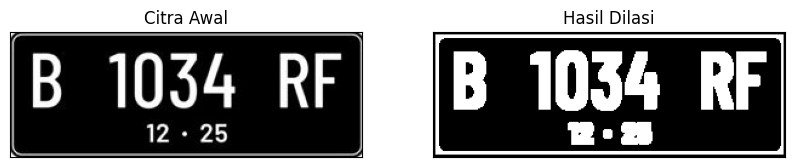

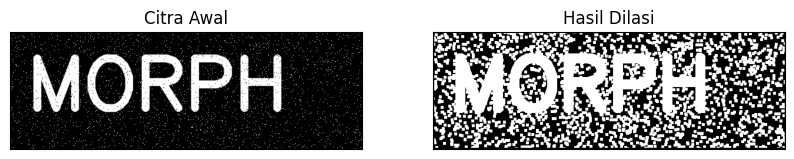

In [7]:
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 125, 200, cv2.THRESH_BINARY)
  w=5
  imgD = dilasi_citra(thresh,w)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title(f'Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title(f'Hasil Dilasi'), plt.xticks([]), plt.yticks([])
  plt.show()

### 4

[[1 1 1]
 [1 1 1]
 [1 1 1]]


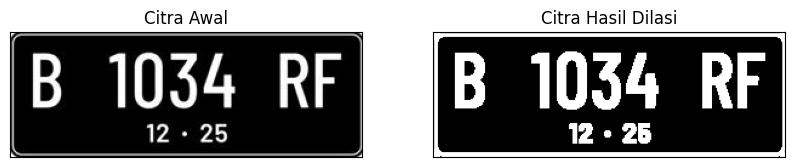

[[1 1 1]
 [1 1 1]
 [1 1 1]]


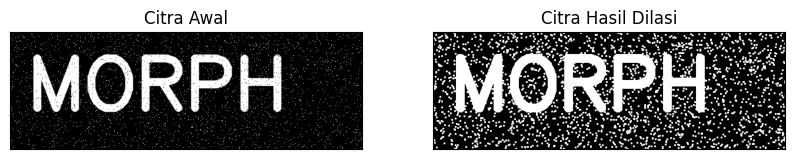

In [8]:
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  kernel = np.ones((3,3),np.uint16)
  dilasi = cv2.dilate(thresh,kernel,iterations = 1)
  print(kernel)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i], cmap='gray'),plt.title('Citra Awal')
  plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(dilasi, cmap='gray'),plt.title('Citra Hasil Dilasi')
  plt.xticks([]), plt.yticks([])
  plt.show()

### 5

In [9]:
#Erosi Tanpa Library
def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

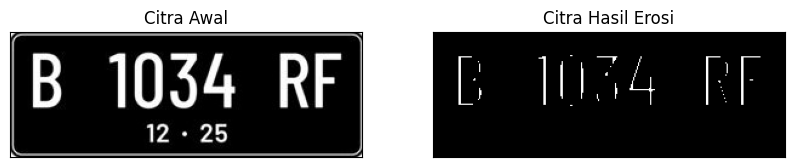

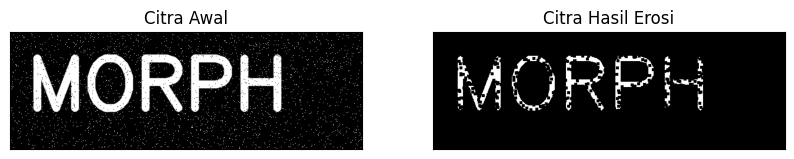

In [10]:
for i in range(0, 2, 1):
  ret1, thresh1 = cv2.threshold(img_list[i], 175, 225, cv2.THRESH_BINARY)
  k=5
  imgE = erosi_citra(thresh1,k)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
  plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
  plt.show()

### 6

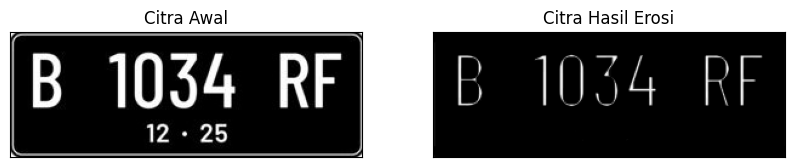

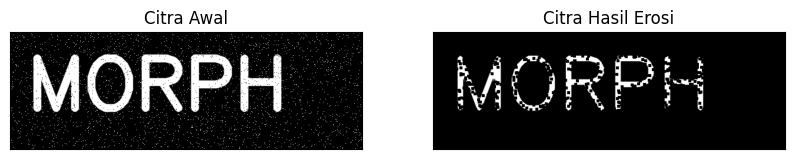

In [11]:
#EROSI LIBRARY
for i in range(0, 2, 1):
  kernel = np.ones((5,5),np.uint8)
  erosion = cv2.erode(img_list[i],kernel,iterations = 1)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i], cmap = 'gray'),plt.title('Citra Awal')
  plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(erosion, cmap = 'gray'),plt.title('Citra Hasil Erosi')
  plt.xticks([]), plt.yticks([])
  plt.show()

### 7

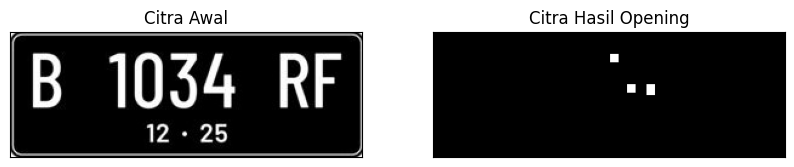

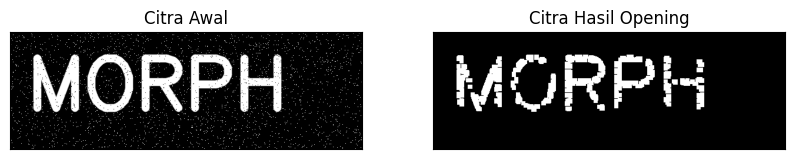

In [12]:
for i in range(0, 2, 1):
  reto, thresho = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  k=7
  imgO = dilasi_citra(erosi_citra(thresho,k),k)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgO,cmap = 'gray')
  plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
  plt.show()

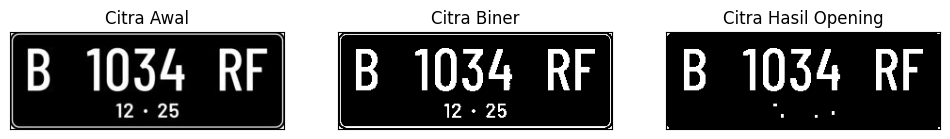

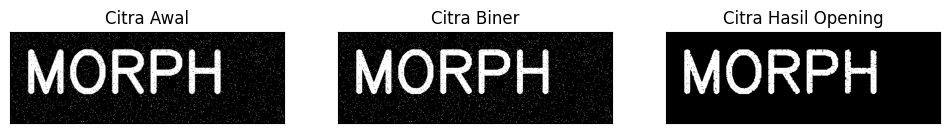

In [13]:
#Dengan Menggunakan Library
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  kernel = np.ones((3,3),np.uint8)
  openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)

  plt.figure(figsize=(12, 4))
  plt.subplot(131),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
  plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
  plt.subplot(133),plt.imshow(openn,cmap = 'gray')
  plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
  plt.show()

### 8

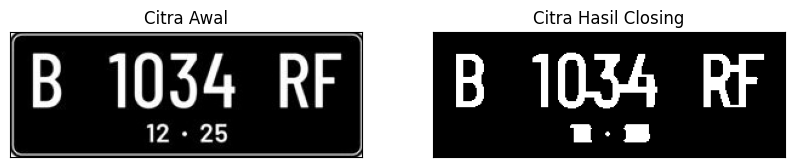

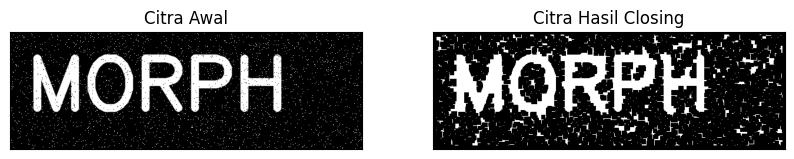

In [14]:
for i in range(0, 2, 1):
  retc, threshc = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  k=7
  imgC = erosi_citra(dilasi_citra(threshc,k),k)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgC,cmap = 'gray')
  plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
  plt.show()

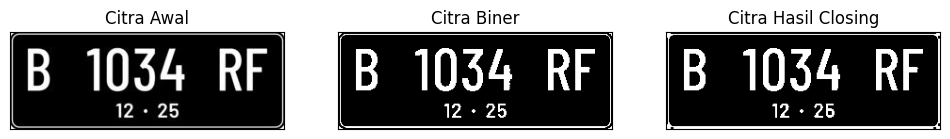

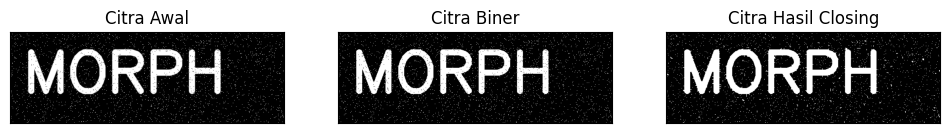

In [15]:
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  kernel = np.ones((3,3),np.uint8)
  closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)

  plt.figure(figsize=(12, 4))
  plt.subplot(131),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
  plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
  plt.subplot(133),plt.imshow(closs,cmap = 'gray')
  plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
  plt.show()

### 9

In [16]:
#Dilasi Cross SED
def dilasi_citra(F,w):
  #size image
  p,q = F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Cross 3


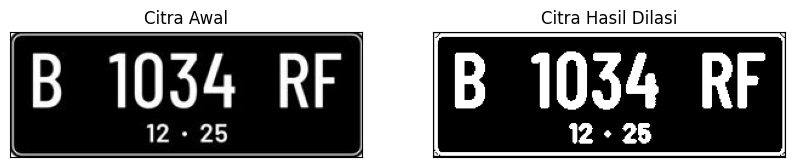

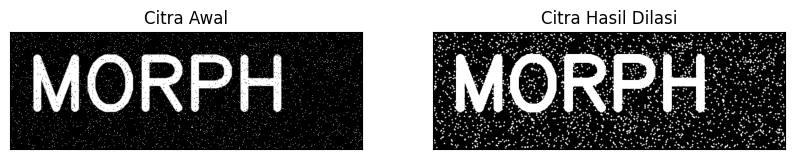

In [17]:
print('SED = Cross 3')
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  w=3
  imgD = dilasi_citra(thresh,w)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
  plt.show()

In [18]:
def dilasi_citra(F,w):
    #size image
    p,q= F.shape

    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    # SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype = np.uint8)

    constant1= (w-1)//2
    #Proses Dilasi
    for i in range(constant1, p-constant1):
      for j in range(constant1,q-constant1):
        temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
        product= temp*SED
        imgD[i,j]= np.max(product)
    return imgD

SED = Cross 5


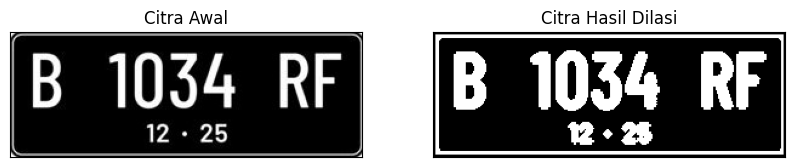

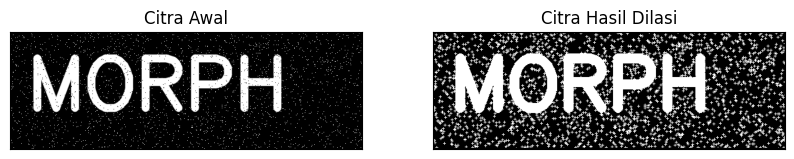

In [19]:
print('SED = Cross 5')
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  w=5
  imgD = dilasi_citra(thresh,w)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
  plt.show()

### 10

In [20]:
#Dilasi Circular SED
def dilasi_citra(F,w):
  #size image
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2
  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Circle 3


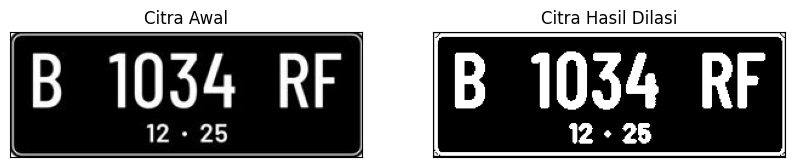

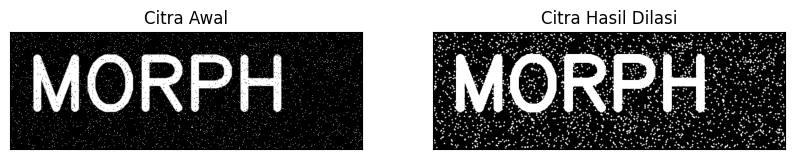

In [21]:
print('SED = Circle 3')
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  w=3
  imgD = dilasi_citra(thresh,w)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
  plt.show()

SED = Circle 5


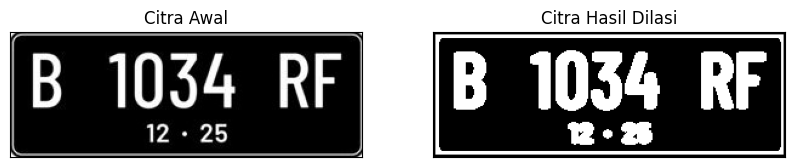

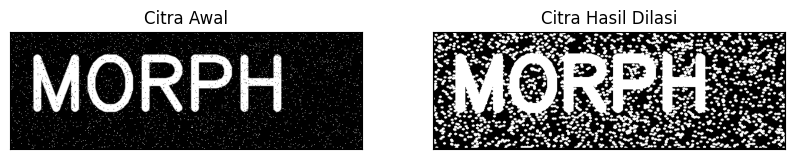

In [22]:
print('SED = Circle 5')
for i in range(0, 2, 1):
  ret, thresh = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  w=5
  imgD = dilasi_citra(thresh,w)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgD,cmap = 'gray')
  plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
  plt.show()

### 11

In [23]:
#Erosi Cross SE
def erosi_citra(F,p,l):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l)) #SE persegi panjang
  constant1= (l-1)//2
  constant2= (p-1)//2
  # print(SE)
  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

SE = Rectangle 3x5


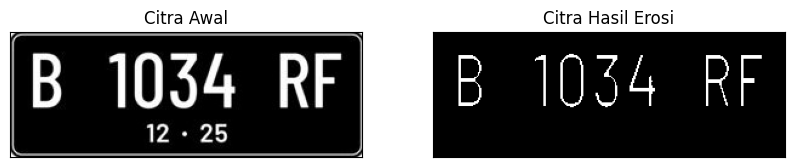

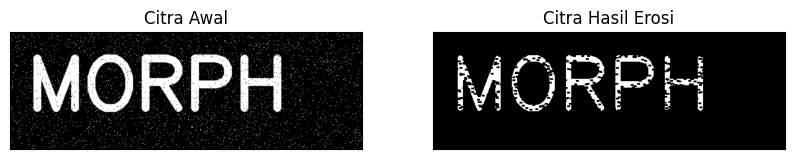

In [24]:
print('SE = Rectangle 3x5')
for i in range(0, 2, 1):
  ret1, thresh1 = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  p=5
  l=3
  imgE = erosi_citra(thresh1,p,l)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
  plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
  plt.show()

SE = Rectangle 5x7


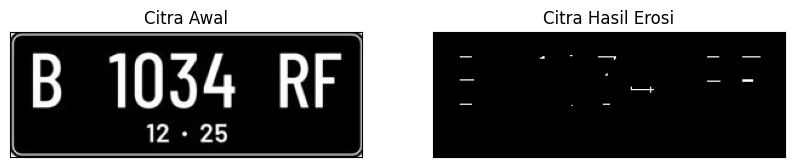

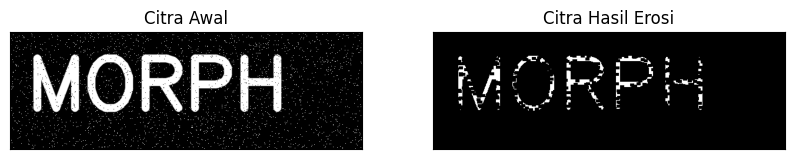

In [25]:
print('SE = Rectangle 5x7')
for i in range(0, 2, 1):
  ret1, thresh1 = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  p=7
  l=5
  imgE = erosi_citra(thresh1,p,l)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
  plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
  plt.show()

### 12

In [26]:
#Erosi Line Vertikal SE
def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k)) #SE line vertikal
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

SE = Line Vertikal 3


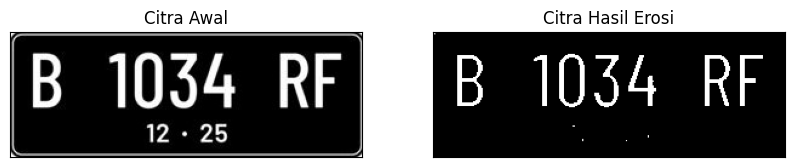

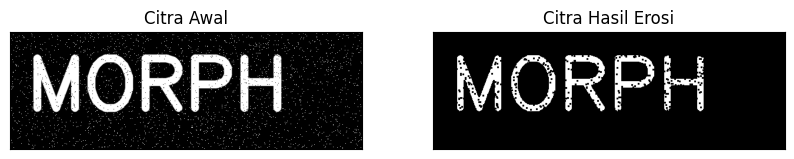

In [27]:
print('SE = Line Vertikal 3')
for i in range(0, 2, 1):
  ret1, thresh1 = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  k=3
  imgE = erosi_citra(thresh1,k)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
  plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
  plt.show()

SE = Line Vertikal 5


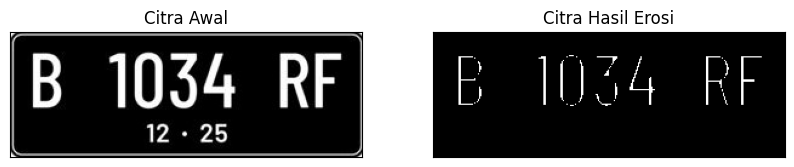

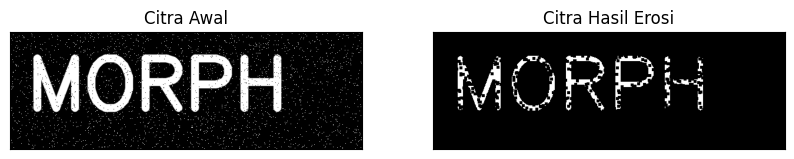

In [28]:
print('SE = Line Vertikal 5')
for i in range(0, 2, 1):
  ret1, thresh1 = cv2.threshold(img_list[i], 127, 225, cv2.THRESH_BINARY)
  k=5
  imgE = erosi_citra(thresh1,k)

  plt.figure(figsize=(10, 5))
  plt.subplot(121),plt.imshow(img_list[i],cmap = 'gray')
  plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(imgE,cmap = 'gray')
  plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
  plt.show()

### 13

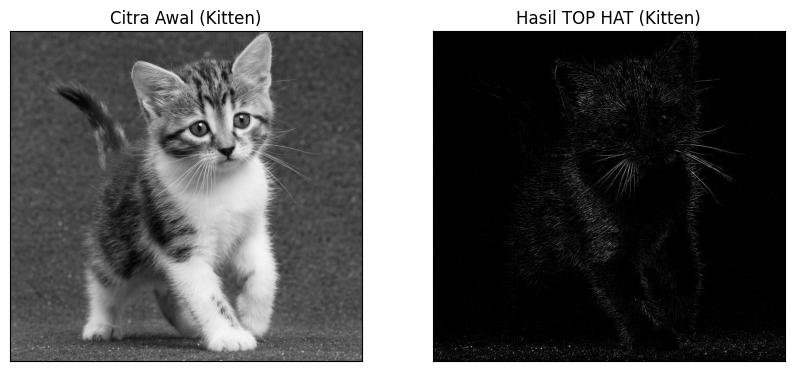

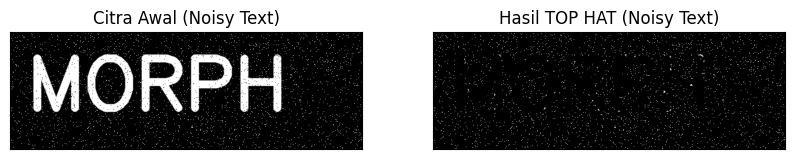

In [34]:
# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Memproses kitten01.jpg (index 2) dan noisy_text.png (index 1) dari img_list
for idx, name in [(2, 'Kitten'), (1, 'Noisy Text')]:
    img = img_list[idx]

    # Applying the Top-Hat operation
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

    plt.figure(figsize=(10, 5))
    plt.subplot(121), plt.imshow(img, cmap='gray')
    plt.title(f'Citra Awal ({name})'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(tophat_img, cmap='gray')
    plt.title(f'Hasil TOP HAT ({name})'), plt.xticks([]), plt.yticks([])
    plt.show()

### 14

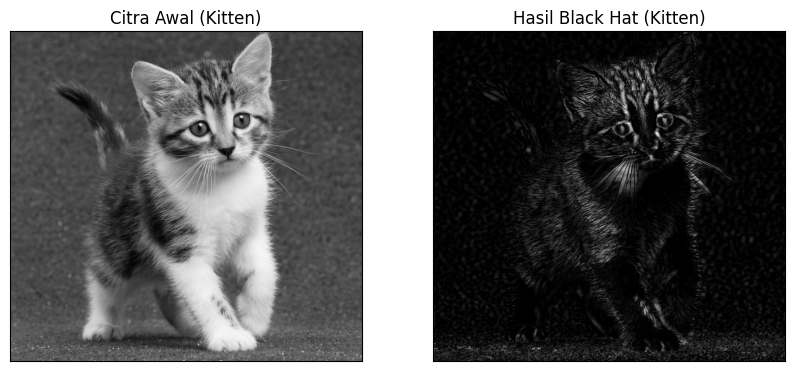

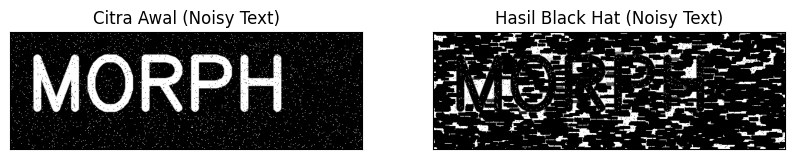

In [35]:
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

# Memproses kitten01.jpg (index 2) dan noisy_text.png (index 1) dari img_list
for idx, name in [(2, 'Kitten'), (1, 'Noisy Text')]:
    img = img_list[idx]

    # Applying the Black-Hat operation
    blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

    plt.figure(figsize=(10, 5))
    plt.subplot(121), plt.imshow(img, cmap='gray')
    plt.title(f'Citra Awal ({name})'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(blackhat, cmap='gray')
    plt.title(f'Hasil Black Hat ({name})'), plt.xticks([]), plt.yticks([])
    plt.show()

### 15

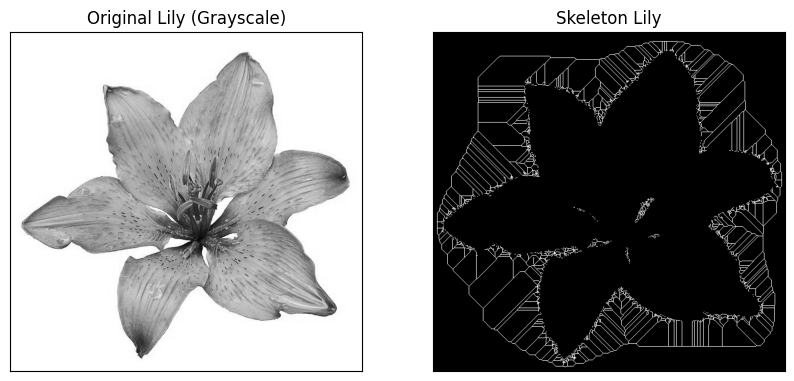

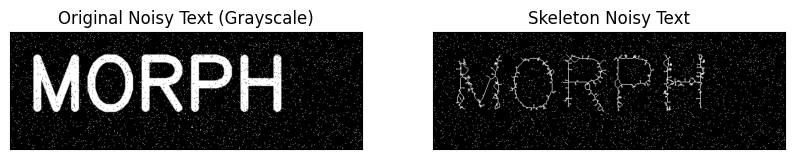

In [36]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
import numpy as np

# Memproses lily.jpg (index 3) dan noisy_text.png (index 1) dari img_list
for idx, name in [(3, 'Lily'), (1, 'Noisy Text')]:
    img_gray = img_list[idx]

    # Apply thresholding on grayscale image
    binary = img_gray > filters.threshold_triangle(img_gray)

    # convert boolean True/False to 1/0
    binary_cp = binary.astype(np.uint8)

    # skeletonize image
    skeleton = skeletonize(binary_cp)

    # print images
    plt.figure(figsize=(10, 5))
    plt.subplot(121), plt.imshow(img_gray, cmap='gray')
    plt.title(f'Original {name} (Grayscale)'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(skeleton, cmap='gray')
    plt.title(f'Skeleton {name}'), plt.xticks([]), plt.yticks([])
    plt.show()

### 16

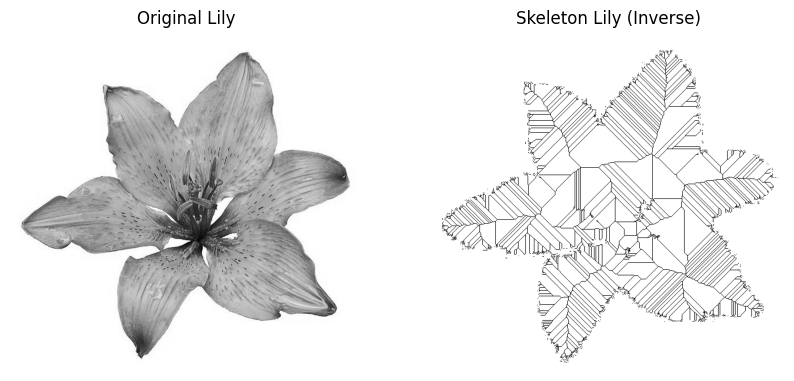

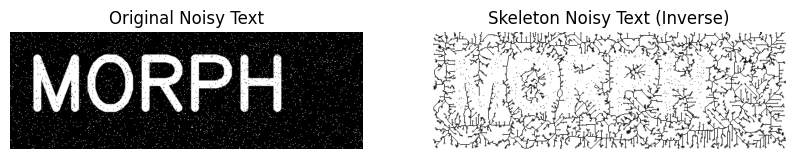

In [37]:
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Memproses lily.jpg (index 3) dan noisy_text.png (index 1) dari img_list
for idx, name in [(3, 'Lily'), (1, 'Noisy Text')]:
    img = img_list[idx]

    # Note: we want the black bits to be True, so use <
    binary = img < filters.threshold_triangle(img)

    # skeletonize image
    skeleton = skeletonize(binary)

    # print images
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'Original {name}')
    ax[0].set_axis_off()

    # note the reversed colormap, gray_r
    ax[1].imshow(skeleton, cmap='gray_r')
    ax[1].set_title(f'Skeleton {name} (Inverse)')
    ax[1].set_axis_off()
    plt.show()

### 17

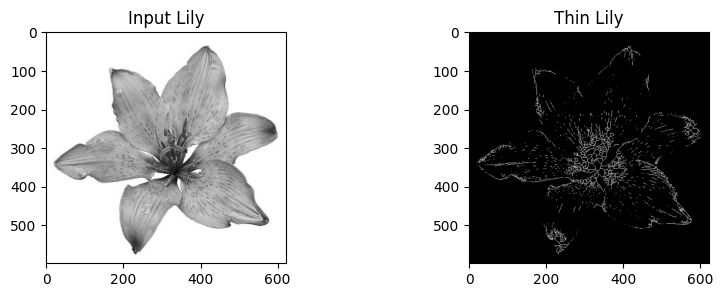

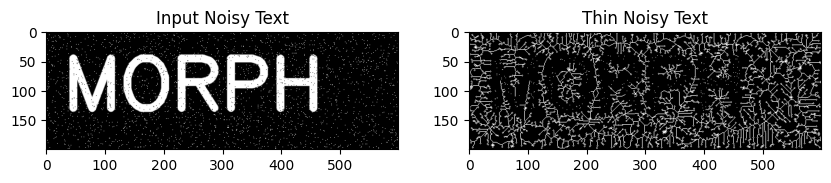

In [38]:
from skimage import img_as_float
from skimage import morphology
import matplotlib.pyplot as plt

# Memproses lily.jpg (index 3) dan noisy_text.png (index 1) dari img_list
for idx, name in [(3, 'Lily'), (1, 'Noisy Text')]:
    # Mengubah data gambar ke format float
    image = img_as_float(img_list[idx])
    image_binary = image < 0.5
    out_thin = morphology.thin(image_binary)

    f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

    ax0.imshow(image, cmap='gray')
    ax0.set_title(f'Input {name}')

    ax1.imshow(out_thin, cmap='gray')
    ax1.set_title(f'Thin {name}')
    plt.show()